In [1]:
!pip install -q timm torchmetrics thop grad-cam kaggle torchinfo

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## 2. Imports and reproducibility

In [2]:
import os
import json
import random
import shutil
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import timm

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, matthews_corrcoef, confusion_matrix,
    classification_report
)
from thop import profile
from torchinfo import summary

sns.set_style("darkgrid")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"
print("Device:", device)
print("Mixed precision:", USE_AMP)
print("timm version:", timm.__version__)
from timm.models.vision_transformer import VisionTransformer


Device: cuda
Mixed precision: True
timm version: 1.0.30


## 3. Kaggle authentication

For safety, this notebook does **not** contain the Kaggle API key from the source notebook. Upload your own `kaggle.json` downloaded from your Kaggle account (**Kaggle → Settings → API → Create New Token**). If running outside Colab, place the file at `~/.kaggle/kaggle.json` yourself.

In [3]:
# Google Colab: upload kaggle.json when prompted.
try:
    from google.colab import files
    uploaded = files.upload()
    if "kaggle.json" not in uploaded:
        raise FileNotFoundError("Please upload a file named kaggle.json")
    kaggle_dir = Path.home() / ".kaggle"
    kaggle_dir.mkdir(parents=True, exist_ok=True)
    with open(kaggle_dir / "kaggle.json", "wb") as f:
        f.write(uploaded["kaggle.json"])
    os.chmod(kaggle_dir / "kaggle.json", 0o600)
    print("Kaggle credentials configured.")
except ImportError:
    kaggle_path = Path.home() / ".kaggle" / "kaggle.json"
    if not kaggle_path.exists():
        raise FileNotFoundError(
            f"Place your Kaggle API token at {kaggle_path} before continuing."
        )
    os.chmod(kaggle_path, 0o600)
    print("Using existing Kaggle credentials:", kaggle_path)

Saving kaggle.json to kaggle.json
Kaggle credentials configured.


## 4. Download the same dataset

In [4]:
from kaggle.api.kaggle_api_extended import KaggleApi

DATA_DIR = Path("brain_tumor_mri_data")
DATASET = "sartajbhuvaji/brain-tumor-classification-mri"

if not DATA_DIR.exists() or not any(DATA_DIR.iterdir()):
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    api = KaggleApi()
    api.authenticate()
    api.dataset_download_files(DATASET, path=str(DATA_DIR), unzip=True)

print("Dataset directory:", DATA_DIR.resolve())
print("Top-level entries:", [p.name for p in DATA_DIR.iterdir()][:20])

Dataset URL: https://www.kaggle.com/datasets/sartajbhuvaji/brain-tumor-classification-mri
Dataset directory: /content/brain_tumor_mri_data
Top-level entries: ['Testing', 'Training']


## 5. Build the image dataframe

In [5]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png"}

# Locate the directory whose immediate subfolders are the image classes.
class_root_candidates = []
for root, dirs, files in os.walk(DATA_DIR):
    root_path = Path(root)
    valid_class_dirs = []
    for dirname in dirs:
        child = root_path / dirname
        image_count = sum(1 for p in child.iterdir()
                          if p.is_file() and p.suffix.lower() in IMAGE_EXTS)
        if image_count > 0:
            valid_class_dirs.append((child, image_count))
    if len(valid_class_dirs) >= 2:
        class_root_candidates.append((root_path, sum(n for _, n in valid_class_dirs), valid_class_dirs))

if not class_root_candidates:
    raise RuntimeError(
        "Could not identify class folders. Inspect the extracted dataset structure and set DATA_ROOT manually."
    )

# Prefer the candidate with the largest number of images in its immediate class folders.
DATA_ROOT, _, class_dirs_info = max(class_root_candidates, key=lambda x: x[1])
class_names = sorted([p.name for p, _ in class_dirs_info])
label_map = {name: idx for idx, name in enumerate(class_names)}
idx_to_class = {idx: name for name, idx in label_map.items()}

records = []
for class_name in class_names:
    class_dir = DATA_ROOT / class_name
    for image_path in sorted(class_dir.iterdir()):
        if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTS:
            records.append({
                "image_path": str(image_path),
                "label": label_map[class_name],
                "class_name": class_name
            })

df = pd.DataFrame(records)
if df.empty:
    raise RuntimeError(f"No images found under {DATA_ROOT}")

num_classes = len(class_names)
print("Selected data root:", DATA_ROOT)
print("Classes:", label_map)
print("Total images:", len(df))
print("Class distribution:\n", df["class_name"].value_counts())
display(df.head())

Selected data root: brain_tumor_mri_data/Training
Classes: {'glioma_tumor': 0, 'meningioma_tumor': 1, 'no_tumor': 2, 'pituitary_tumor': 3}
Total images: 2870
Class distribution:
 class_name
pituitary_tumor     827
glioma_tumor        826
meningioma_tumor    822
no_tumor            395
Name: count, dtype: int64


,image_path,label,class_name
0,brain_tumor_mri_data/Training/glioma_tumor/gg ...,0,glioma_tumor
1,brain_tumor_mri_data/Training/glioma_tumor/gg ...,0,glioma_tumor
2,brain_tumor_mri_data/Training/glioma_tumor/gg ...,0,glioma_tumor
3,brain_tumor_mri_data/Training/glioma_tumor/gg ...,0,glioma_tumor
4,brain_tumor_mri_data/Training/glioma_tumor/gg ...,0,glioma_tumor


## 6. Train / validation / test split

In [6]:
train_df, test_df = train_test_split(
    df, test_size=0.20, stratify=df["label"], random_state=SEED
)
train_df, val_df = train_test_split(
    train_df, test_size=0.20, stratify=train_df["label"], random_state=SEED
)

print(f"Train: {len(train_df)} | Validation: {len(val_df)} | Test: {len(test_df)}")

Train: 1836 | Validation: 460 | Test: 574


## 7. Dataset, transforms, and dataloaders

In [7]:
class BrainTumorDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(row["image_path"]).convert("RGB")
        if self.transform is not None:
            image = self.transform(image)
        return image, torch.tensor(int(row["label"]), dtype=torch.long)

train_transform = transforms.Compose([
    transforms.Resize((448, 448)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.95, 1.05)),
    transforms.ColorJitter(brightness=0.10, contrast=0.10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_test_transform = transforms.Compose([
    transforms.Resize((448, 448)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

BATCH_SIZE = 8  # Memory-conscious for ConvNeXt + CBAM + ViT
NUM_WORKERS = 2
pin_memory = device.type == "cuda"

train_loader = DataLoader(BrainTumorDataset(train_df, train_transform),
                          batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=pin_memory)
val_loader = DataLoader(BrainTumorDataset(val_df, val_test_transform),
                        batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=pin_memory)
test_loader = DataLoader(BrainTumorDataset(test_df, val_test_transform),
                         batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=pin_memory)

print("Batches:", len(train_loader), len(val_loader), len(test_loader))

Batches: 230 58 72


In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm

from timm.models.vision_transformer import VisionTransformer


# ============================================================
# 1. SURROGATE SPIKE FUNCTION
# ============================================================

class SurrogateSpike(torch.autograd.Function):

    @staticmethod
    def forward(ctx, x):
        ctx.save_for_backward(x)
        return (x > 0).float()

    @staticmethod
    def backward(ctx, grad_output):

        (x,) = ctx.saved_tensors

        slope = 5.0

        grad = 1.0 / (
            1.0 + slope * torch.abs(x)
        ) ** 2

        return grad_output * grad


# ============================================================
# 2. LIF NEURON
# ============================================================

class LIFNeuron(nn.Module):

    def __init__(
        self,
        threshold=1.0,
        beta=0.97,
        num_steps=4
    ):

        super().__init__()

        self.threshold = threshold
        self.beta = beta
        self.num_steps = num_steps

    def forward(self, current):

        membrane = torch.zeros_like(current)

        spike_sequence = []

        for t in range(self.num_steps):

            membrane = (
                self.beta * membrane + current
            )

            spike = SurrogateSpike.apply(
                membrane - self.threshold
            )

            membrane = (
                membrane -
                spike.detach() * self.threshold
            )

            spike_sequence.append(spike)

        return torch.stack(
            spike_sequence,
            dim=0
        ).mean(dim=0)


# ============================================================
# 3. SINGLE SNN BLOCK
# ============================================================

class SNNBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        kernel_size=3,
        padding=1,
        beta=0.97,
        threshold=1.0,
        num_steps=4
    ):

        super().__init__()

        self.conv = nn.Conv2d(
            in_channels=in_channels,
            out_channels=out_channels,
            kernel_size=kernel_size,
            stride=1,
            padding=padding,
            bias=False
        )

        self.bn = nn.BatchNorm2d(
            out_channels
        )

        self.lif = LIFNeuron(
            threshold=threshold,
            beta=beta,
            num_steps=num_steps
        )

        self.skip = (
            nn.Identity()
            if in_channels == out_channels
            else nn.Sequential(
                nn.Conv2d(
                    in_channels,
                    out_channels,
                    kernel_size=1,
                    bias=False
                ),
                nn.BatchNorm2d(out_channels)
            )
        )

    def forward(self, x):

        identity = self.skip(x)

        current = self.conv(x)

        current = self.bn(current)

        spike_output = self.lif(current)

        return identity + spike_output


# ============================================================
# 4. CBAM MODULE
# ============================================================

class ChannelAttention(nn.Module):

    def __init__(
        self,
        channels,
        reduction=16
    ):

        super().__init__()

        hidden_channels = max(
            channels // reduction,
            1
        )

        self.shared_mlp = nn.Sequential(

            nn.Conv2d(
                channels,
                hidden_channels,
                kernel_size=1,
                bias=False
            ),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                hidden_channels,
                channels,
                kernel_size=1,
                bias=False
            )
        )

    def forward(self, x):

        avg_pool = F.adaptive_avg_pool2d(
            x, 1
        )

        max_pool = F.adaptive_max_pool2d(
            x, 1
        )

        avg_out = self.shared_mlp(
            avg_pool
        )

        max_out = self.shared_mlp(
            max_pool
        )

        attention = torch.sigmoid(
            avg_out + max_out
        )

        return x * attention


class SpatialAttention(nn.Module):

    def __init__(self, kernel_size=7):

        super().__init__()

        self.conv = nn.Conv2d(
            2,
            1,
            kernel_size=kernel_size,
            padding=kernel_size // 2,
            bias=False
        )

    def forward(self, x):

        avg_pool = torch.mean(
            x,
            dim=1,
            keepdim=True
        )

        max_pool = torch.max(
            x,
            dim=1,
            keepdim=True
        )[0]

        combined = torch.cat(
            [avg_pool, max_pool],
            dim=1
        )

        attention = torch.sigmoid(
            self.conv(combined)
        )

        return x * attention


class CBAM(nn.Module):

    def __init__(
        self,
        channels,
        reduction=16,
        spatial_kernel=7
    ):

        super().__init__()

        self.channel_attention = ChannelAttention(
            channels,
            reduction
        )

        self.spatial_attention = SpatialAttention(
            spatial_kernel
        )

    def forward(self, x):

        x = self.channel_attention(x)

        x = self.spatial_attention(x)

        return x


# ============================================================
# 5. CBAM DILATED CONVOLUTION BRANCH
# ============================================================

class CBAMBranch(nn.Module):

    def __init__(self, in_channels=192):

        super().__init__()

        # CBAM attention on ConvNeXt feature map

        self.cbam = CBAM(
            channels=in_channels,
            reduction=16,
            spatial_kernel=7
        )

        # Max pooling: 56 x 56 -> 28 x 28

        self.max_pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        # Dilated convolution:
        # 192 channels -> 96 channels
        # dilation rate = 2

        self.dilated_conv = nn.Sequential(

            nn.Conv2d(
                in_channels=in_channels,
                out_channels=96,
                kernel_size=3,
                stride=1,
                padding=2,
                dilation=2,
                bias=False
            ),

            nn.BatchNorm2d(96),

            nn.ReLU(inplace=True)
        )

        # Global Average Pooling

        self.gap = nn.AdaptiveAvgPool2d(
            (1, 1)
        )

    def forward(self, x):

        # B, 192, 56, 56

        x = self.cbam(x)

        # B, 192, 56, 56

        x = self.max_pool(x)

        # B, 192, 28, 28

        x = self.dilated_conv(x)

        # B, 96, 28, 28

        x = self.gap(x)

        # B, 96, 1, 1

        x = torch.flatten(
            x,
            start_dim=1
        )

        # B, 96

        return x


# ============================================================
# 6. MAIN SNN + ViT BRANCH
# ============================================================

class SNNViTBranch(nn.Module):

    def __init__(self):

        super().__init__()

        # Only ONE SNN block

        self.snn_block = SNNBlock(
            in_channels=192,
            out_channels=128,
            kernel_size=3,
            padding=1,
            beta=0.97,
            threshold=1.0,
            num_steps=4
        )

        # Max pooling: 56 x 56 -> 28 x 28

        self.max_pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        # 1 x 1 convolution: 128 -> 96

        self.conv1x1 = nn.Sequential(

            nn.Conv2d(
                in_channels=128,
                out_channels=96,
                kernel_size=1,
                stride=1,
                padding=0,
                bias=False
            ),

            nn.BatchNorm2d(96),

            nn.ReLU(inplace=True)
        )

        # 3 x 3 convolution: 96 -> 64

        self.conv3x3 = nn.Sequential(

            nn.Conv2d(
                in_channels=96,
                out_channels=64,
                kernel_size=3,
                stride=1,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(64),

            nn.ReLU(inplace=True)
        )

        # Vision Transformer
        #
        # Input feature map: 64 x 28 x 28
        # Patch size: 7 x 7
        # Number of patches: 4 x 4 = 16

        self.vit_encoder = VisionTransformer(

            img_size=28,

            patch_size=7,

            in_chans=64,

            num_classes=0,

            global_pool="avg",

            embed_dim=64,

            depth=2,

            num_heads=4,

            mlp_ratio=1,

            qkv_bias=True,

            norm_layer=nn.LayerNorm,

            act_layer=nn.ReLU
        )

        self.vit_encoder.head = nn.Identity()

    def forward(self, x):

        # Input: B, 192, 56, 56

        x = self.snn_block(x)

        # B, 128, 56, 56

        x = self.max_pool(x)

        # B, 128, 28, 28

        x = self.conv1x1(x)

        # B, 96, 28, 28

        x = self.conv3x3(x)

        # B, 64, 28, 28

        x = self.vit_encoder(x)

        # B, 64

        return x


# ============================================================
# 7. COMPLETE CONVNEXT + SNN + CBAM + ViT MODEL
# ============================================================

class ConvNeXtSNNViTCBAM(nn.Module):

    def __init__(
        self,
        num_classes,
        pretrained=True
    ):

        super().__init__()

        # ----------------------------------------------------
        # ConvNeXt-Tiny Backbone
        # ----------------------------------------------------

        base = timm.create_model(

            "convnext_tiny",

            pretrained=pretrained,

            num_classes=0
        )

        self.stem = base.stem

        stage1 = base.stages[0]

        stage2 = base.stages[1]

        # Retain only first block of stage 2

        stage2.blocks = nn.Sequential(
            *list(stage2.blocks.children())[:1]
        )

        self.stages = nn.Sequential(
            stage1,
            stage2
        )

        del base

        self.feature_channels = 192

        # ----------------------------------------------------
        # Main SNN + ViT Branch
        # ----------------------------------------------------

        self.main_branch = SNNViTBranch()

        # ----------------------------------------------------
        # Parallel CBAM Branch
        # ----------------------------------------------------

        self.cbam_branch = CBAMBranch(
            in_channels=192
        )

        # ----------------------------------------------------
        # Feature Concatenation
        # ----------------------------------------------------

        self.fusion_dim = 64 + 96

        # ----------------------------------------------------
        # Final Classifier
        # ----------------------------------------------------

        self.classifier = nn.Linear(
            self.fusion_dim,
            num_classes
        )

    # --------------------------------------------------------
    # ConvNeXt Feature Extraction
    # --------------------------------------------------------

    def forward_features(self, x):

        x = self.stem(x)

        x = self.stages(x)

        return x

    # --------------------------------------------------------
    # Complete Feature Extraction
    # --------------------------------------------------------

    def forward_head_features(self, x):

        # Shared ConvNeXt features

        backbone_features = self.forward_features(x)

        # B, 192, 56, 56

        # Main branch: SNN + ViT

        vit_features = self.main_branch(
            backbone_features
        )

        # B, 64

        # Parallel branch: CBAM + Dilated Conv + GAP

        cbam_features = self.cbam_branch(
            backbone_features
        )

        # B, 96

        # Feature concatenation

        fused_features = torch.cat(

            [
                vit_features,
                cbam_features
            ],

            dim=1
        )

        # B, 160

        return fused_features

    # --------------------------------------------------------
    # Final Forward Pass
    # --------------------------------------------------------

    def forward(self, x):

        fused_features = self.forward_head_features(x)

        logits = self.classifier(fused_features)

        return logits


# ============================================================
# 8. MODEL INITIALIZATION
# ============================================================

model = ConvNeXtSNNViTCBAM(

    num_classes=num_classes,

    pretrained=True

).to(device)


# ============================================================
# 9. ARCHITECTURE VERIFICATION
# ============================================================

model.eval()

with torch.no_grad():

    dummy = torch.randn(

        1,
        3,
        448,
        448,

        device=device
    )

    # ConvNeXt output

    backbone_map = model.forward_features(dummy)

    # Main branch

    snn_map = model.main_branch.snn_block(
        backbone_map
    )

    pooled_snn = model.main_branch.max_pool(
        snn_map
    )

    conv1x1_map = model.main_branch.conv1x1(
        pooled_snn
    )

    conv3x3_map = model.main_branch.conv3x3(
        conv1x1_map
    )

    vit_features = model.main_branch.vit_encoder(
        conv3x3_map
    )

    # CBAM branch

    cbam_map = model.cbam_branch.cbam(
        backbone_map
    )

    cbam_pooled = model.cbam_branch.max_pool(
        cbam_map
    )

    dilated_map = model.cbam_branch.dilated_conv(
        cbam_pooled
    )

    cbam_gap = model.cbam_branch.gap(
        dilated_map
    )

    cbam_features = torch.flatten(
        cbam_gap,
        start_dim=1
    )

    # Concatenation

    fused_features = torch.cat(

        [
            vit_features,
            cbam_features
        ],

        dim=1
    )

    # Final output

    logits = model(dummy)

    probabilities = torch.softmax(
        logits,
        dim=1
    )


# ============================================================
# 10. PRINT ALL DIMENSIONS
# ============================================================

retained_block_counts = [

    len(stage.blocks)

    for stage in model.stages
]

print("\n========== ARCHITECTURE VERIFICATION ==========\n")

print(
    "Retained ConvNeXt blocks:",
    retained_block_counts
)

print(
    "ConvNeXt output:",
    tuple(backbone_map.shape)
)

print(
    "After single SNN block:",
    tuple(snn_map.shape)
)

print(
    "After main branch max pooling:",
    tuple(pooled_snn.shape)
)

print(
    "After 1x1 convolution:",
    tuple(conv1x1_map.shape)
)

print(
    "After 3x3 convolution:",
    tuple(conv3x3_map.shape)
)

print(
    "ViT output:",
    tuple(vit_features.shape)
)

print("\n---------- CBAM BRANCH ----------\n")

print(
    "After CBAM:",
    tuple(cbam_map.shape)
)

print(
    "After CBAM max pooling:",
    tuple(cbam_pooled.shape)
)

print(
    "After dilated convolution:",
    tuple(dilated_map.shape)
)

print(
    "After GAP:",
    tuple(cbam_features.shape)
)

print("\n---------- FEATURE FUSION ----------\n")

print(
    "Concatenated features:",
    tuple(fused_features.shape)
)

print(
    "Classifier output:",
    tuple(logits.shape)
)

print(
    "Softmax probabilities:",
    tuple(probabilities.shape)
)


# ============================================================
# 11. DIMENSION ASSERTIONS
# ============================================================

assert retained_block_counts == [3, 1]

assert tuple(backbone_map.shape[1:]) == (
    192, 56, 56
)

assert tuple(snn_map.shape[1:]) == (
    128, 56, 56
)

assert tuple(pooled_snn.shape[1:]) == (
    128, 28, 28
)

assert tuple(conv1x1_map.shape[1:]) == (
    96, 28, 28
)

assert tuple(conv3x3_map.shape[1:]) == (
    64, 28, 28
)

assert tuple(vit_features.shape) == (
    1, 64
)

assert tuple(cbam_map.shape[1:]) == (
    192, 56, 56
)

assert tuple(cbam_pooled.shape[1:]) == (
    192, 28, 28
)

assert tuple(dilated_map.shape[1:]) == (
    96, 28, 28
)

assert tuple(cbam_features.shape) == (
    1, 96
)

assert tuple(fused_features.shape) == (
    1, 160
)

assert tuple(logits.shape) == (
    1, num_classes
)

assert tuple(probabilities.shape) == (
    1, num_classes
)

print("\nAll architecture dimensions verified successfully!")

model.train()

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            


========== ARCHITECTURE VERIFICATION ==========

Retained ConvNeXt blocks: [3, 1]
ConvNeXt output: (1, 192, 56, 56)
After single SNN block: (1, 128, 56, 56)
After main branch max pooling: (1, 128, 28, 28)
After 1x1 convolution: (1, 96, 28, 28)
After 3x3 convolution: (1, 64, 28, 28)
ViT output: (1, 64)

---------- CBAM BRANCH ----------

After CBAM: (1, 192, 56, 56)
After CBAM max pooling: (1, 192, 28, 28)
After dilated convolution: (1, 96, 28, 28)
After GAP: (1, 96)

---------- FEATURE FUSION ----------

Concatenated features: (1, 160)
Classifier output: (1, 4)
Softmax probabilities: (1, 4)

All architecture dimensions verified successfully!


ConvNeXtSNNViTCBAM(
  (stem): Sequential(
    (0): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
    (1): LayerNorm2d((96,), eps=1e-06, elementwise_affine=True)
  )
  (stages): Sequential(
    (0): ConvNeXtStage(
      (downsample): Identity()
      (blocks): Sequential(
        (0): ConvNeXtBlock(
          (conv_dw): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)
          (norm): LayerNorm((96,), eps=1e-06, elementwise_affine=True)
          (mlp): Mlp(
            (fc1): Linear(in_features=96, out_features=384, bias=True)
            (act): GELU()
            (drop1): Dropout(p=0.0, inplace=False)
            (norm): Identity()
            (fc2): Linear(in_features=384, out_features=96, bias=True)
            (drop2): Dropout(p=0.0, inplace=False)
          )
          (shortcut): Identity()
          (drop_path): Identity()
        )
        (1): ConvNeXtBlock(
          (conv_dw): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), g

## 9. Model summary and complexity

The model summary includes the four retained ConvNeXt blocks, CBAM, and classification head.

In [9]:
summary(
    model,
    input_size=(1, 3, 448, 448),
    col_names=["input_size", "output_size", "num_params", "kernel_size"],
    depth=4
)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())
print(f"Trainable parameters: {trainable_params:,}")
print(f"Total parameters: {total_params:,}")

model.eval()
dummy_input = torch.randn(1, 3, 448, 448, device=device)
flops, thop_params = profile(model, inputs=(dummy_input,), verbose=False)
print(f"THOP FLOPs: {flops:,.0f} ({flops / 1e9:.4f} GFLOPs)")
print(f"THOP parameters: {thop_params:,.0f} ({thop_params / 1e6:.4f} M)")
model.train()

Trainable parameters: 1,361,030
Total parameters: 1,361,030
THOP FLOPs: 5,157,130,848 (5.1571 GFLOPs)
THOP parameters: 1,358,054 (1.3581 M)


ConvNeXtSNNViTCBAM(
  (stem): Sequential(
    (0): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
    (1): LayerNorm2d((96,), eps=1e-06, elementwise_affine=True)
  )
  (stages): Sequential(
    (0): ConvNeXtStage(
      (downsample): Identity()
      (blocks): Sequential(
        (0): ConvNeXtBlock(
          (conv_dw): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)
          (norm): LayerNorm((96,), eps=1e-06, elementwise_affine=True)
          (mlp): Mlp(
            (fc1): Linear(in_features=96, out_features=384, bias=True)
            (act): GELU()
            (drop1): Dropout(p=0.0, inplace=False)
            (norm): Identity()
            (fc2): Linear(in_features=384, out_features=96, bias=True)
            (drop2): Dropout(p=0.0, inplace=False)
          )
          (shortcut): Identity()
          (drop_path): Identity()
        )
        (1): ConvNeXtBlock(
          (conv_dw): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), g

## 10. Loss, optimizer, and learning-rate schedule

In [10]:
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW(
    model.parameters(), lr=3e-4, weight_decay=1e-4, betas=(0.9, 0.999)
)

TOTAL_EPOCHS = 35
WARMUP_EPOCHS = 5
warmup_scheduler = torch.optim.lr_scheduler.LinearLR(
    optimizer, start_factor=0.1, end_factor=1.0, total_iters=WARMUP_EPOCHS
)
cosine_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=TOTAL_EPOCHS - WARMUP_EPOCHS, eta_min=1e-6
)

scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
BEST_MODEL_PATH = "best_convnext_cbam_vit.pth"
print("Checkpoint:", BEST_MODEL_PATH)

Checkpoint: best_convnext_cbam_vit.pth


## 11. Metric helpers

In [11]:
def specificity_sensitivity(y_true, y_pred, n_classes):
    cm = confusion_matrix(y_true, y_pred, labels=list(range(n_classes)))
    specificity, sensitivity = [], []
    for i in range(n_classes):
        tp = cm[i, i]
        fn = cm[i, :].sum() - tp
        fp = cm[:, i].sum() - tp
        tn = cm.sum() - (tp + fn + fp)
        specificity.append(tn / (tn + fp + 1e-8))
        sensitivity.append(tp / (tp + fn + 1e-8))
    return float(np.mean(specificity)), float(np.mean(sensitivity))


def calculate_metrics(y_true, y_pred, y_prob, n_classes):
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "mcc": matthews_corrcoef(y_true, y_pred),
    }
    try:
        if n_classes == 2:
            metrics["auc"] = roc_auc_score(y_true, y_prob[:, 1])
        else:
            metrics["auc"] = roc_auc_score(y_true, y_prob, multi_class="ovr", average="macro")
    except ValueError:
        metrics["auc"] = float("nan")
    metrics["specificity"], metrics["sensitivity"] = specificity_sensitivity(
        y_true, y_pred, n_classes
    )
    return metrics

In [12]:
!pip install torchinfo thop torchview graphviz -q

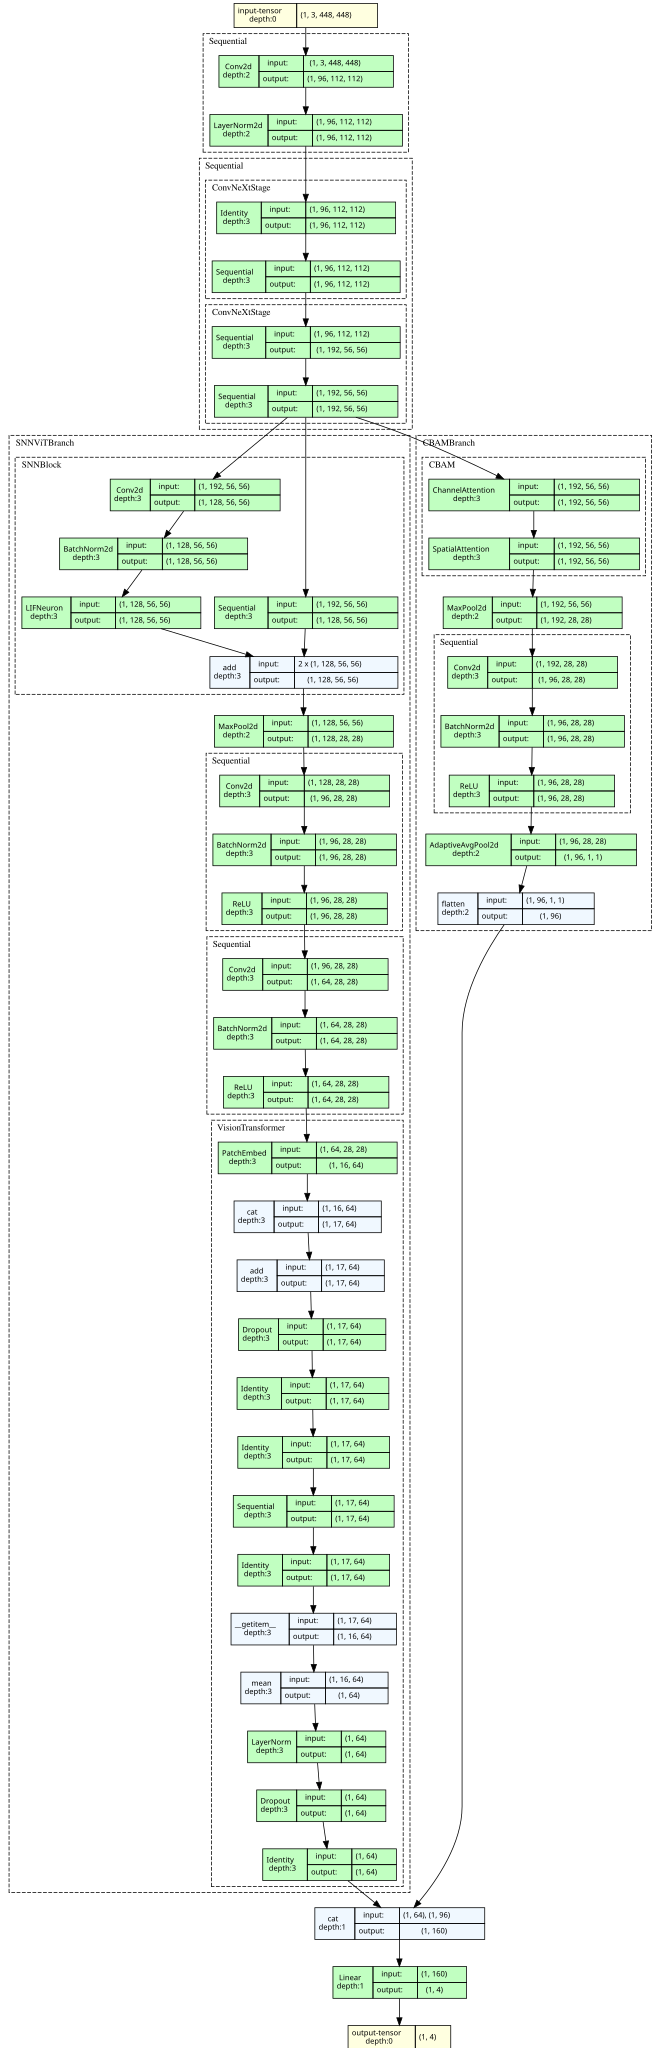

In [13]:
from torchview import draw_graph
from IPython.display import SVG, display

dummy_input = torch.randn(1, 3, 448, 448).to(device)

graph = draw_graph(
    model,
    input_data=dummy_input,
    expand_nested=True,
    graph_name="ConvNeXtCBAMViT",
    save_graph=True,              # IMPORTANT
    filename="ConvNeXtCBAMViT_BlockDiagram",
    directory="."
)

# Display inline
svg = graph.visual_graph.pipe(format="svg")
display(SVG(svg))


## 12. Training and validation

In [14]:

history = {
    "loss": [], "val_loss": [],
    "accuracy": [], "val_accuracy": [],
    "precision": [], "val_precision": [],
    "recall": [], "val_recall": [],
    "f1": [], "val_f1": [],
    "auc": [], "val_auc": [],
    "mcc": [], "val_mcc": [],
    "specificity": [], "val_specificity": [],
    "sensitivity": [], "val_sensitivity": []
}

# Track the best validation accuracy for checkpoint saving.
# No early stopping will be performed.
best_val_acc = -1.0
best_epoch = 0

for epoch in range(TOTAL_EPOCHS):

    # -------------------- TRAIN --------------------
    model.train()
    running_loss = 0.0
    train_true, train_pred, train_prob = [], [], []

    pbar = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{TOTAL_EPOCHS} - Train"
    )

    for images, labels in pbar:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type,
            enabled=USE_AMP
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()

        probs = torch.softmax(outputs.detach(), dim=1)

        train_true.extend(labels.detach().cpu().numpy())
        train_pred.extend(
            outputs.detach().argmax(1).cpu().numpy()
        )
        train_prob.extend(probs.cpu().numpy())

        pbar.set_postfix(
            loss=f"{loss.item():.4f}",
            lr=f"{optimizer.param_groups[0]['lr']:.2e}"
        )

    train_loss = running_loss / max(1, len(train_loader))

    train_metrics = calculate_metrics(
        np.asarray(train_true),
        np.asarray(train_pred),
        np.asarray(train_prob),
        num_classes
    )

    # -------------------- VALIDATION --------------------
    model.eval()

    val_running_loss = 0.0
    val_true, val_pred, val_prob = [], [], []

    with torch.no_grad():

        for images, labels in tqdm(
            val_loader,
            desc=f"Epoch {epoch+1}/{TOTAL_EPOCHS} - Val"
        ):

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.autocast(
                device_type=device.type,
                enabled=USE_AMP
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            val_running_loss += loss.item()

            probs = torch.softmax(outputs, dim=1)

            val_true.extend(labels.cpu().numpy())
            val_pred.extend(outputs.argmax(1).cpu().numpy())
            val_prob.extend(probs.cpu().numpy())

    val_loss = val_running_loss / max(1, len(val_loader))

    val_metrics = calculate_metrics(
        np.asarray(val_true),
        np.asarray(val_pred),
        np.asarray(val_prob),
        num_classes
    )

    # -------------------- LEARNING RATE SCHEDULER --------------------
    if epoch < WARMUP_EPOCHS:
        warmup_scheduler.step()
    else:
        cosine_scheduler.step()

    # -------------------- SAVE HISTORY --------------------
    history["loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    for key in train_metrics:
        history[key].append(train_metrics[key])
        history[f"val_{key}"].append(val_metrics[key])

    # -------------------- PRINT METRICS --------------------
    print(
        f"\nEpoch {epoch+1}/{TOTAL_EPOCHS}: "
        f"train loss={train_loss:.4f}, "
        f"acc={train_metrics['accuracy']:.4f}, "
        f"F1={train_metrics['f1']:.4f}, "
        f"AUC={train_metrics['auc']:.4f} | "
        f"val loss={val_loss:.4f}, "
        f"acc={val_metrics['accuracy']:.4f}, "
        f"F1={val_metrics['f1']:.4f}, "
        f"AUC={val_metrics['auc']:.4f}"
    )

    print(
        f"Val precision={val_metrics['precision']:.4f}, "
        f"recall={val_metrics['recall']:.4f}, "
        f"specificity={val_metrics['specificity']:.4f}, "
        f"sensitivity={val_metrics['sensitivity']:.4f}, "
        f"MCC={val_metrics['mcc']:.4f}"
    )

    print(
        f"Learning rate: "
        f"{optimizer.param_groups[0]['lr']:.6e}"
    )

    # -------------------- SAVE BEST MODEL --------------------
    if val_metrics["accuracy"] > best_val_acc:

        best_val_acc = val_metrics["accuracy"]
        best_epoch = epoch + 1

        torch.save({
            "model_state_dict": model.state_dict(),
            "num_classes": num_classes,
            "class_to_idx": label_map,
            "best_val_accuracy": best_val_acc,
            "epoch": epoch + 1,
            "architecture": "ConvNeXt-Tiny + SNN + CBAM + Vision Transformer + Feature Fusion"
        }, BEST_MODEL_PATH)

        print(
            f"Saved best checkpoint "
            f"(Epoch {best_epoch}, "
            f"Val Accuracy={best_val_acc:.4f})"
        )

    else:
        print(
            f"Best checkpoint retained from Epoch {best_epoch}."
        )

    # NO EARLY STOPPING: training always continues.


# -------------------- FINAL TRAINING SUMMARY --------------------
print("\n" + "=" * 60)
print("TRAINING COMPLETED")
print("=" * 60)

print(f"Total epochs completed: {len(history['loss'])}")
print(f"Best validation accuracy: {best_val_acc:.4f}")
print(f"Best epoch: {best_epoch}")
print(f"Best model saved at: {BEST_MODEL_PATH}")


Epoch 1/35 - Train:   0%|          | 0/230 [00:00<?, ?it/s]

Epoch 1/35 - Val:   0%|          | 0/58 [00:00<?, ?it/s]


Epoch 1/35: train loss=1.0845, acc=0.5507, F1=0.5342, AUC=nan | val loss=0.7719, acc=0.7935, F1=0.7847, AUC=nan
Val precision=0.7904, recall=0.7850, specificity=0.9298, sensitivity=0.7850, MCC=0.7205
Learning rate: 8.400000e-05
Saved best checkpoint (Epoch 1, Val Accuracy=0.7935)


Epoch 2/35 - Train:   0%|          | 0/230 [00:00<?, ?it/s]

Epoch 2/35 - Val:   0%|          | 0/58 [00:00<?, ?it/s]


Epoch 2/35: train loss=0.8430, acc=0.7429, F1=0.7371, AUC=nan | val loss=0.8602, acc=0.7435, F1=0.7129, AUC=nan
Val precision=0.7786, recall=0.7641, specificity=0.9136, sensitivity=0.7641, MCC=0.6821
Learning rate: 1.380000e-04
Best checkpoint retained from Epoch 1.


... (129 outputs left out)

Epoch 35/35 - Train:   0%|          | 0/230 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a891822d300>
Traceback (most recent call last):
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a891822d300>  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__

    self._shutdown_workers()Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
if w.is_alive():    
if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a

Epoch 35/35 - Val:   0%|          | 0/58 [00:00<?, ?it/s]


Epoch 35/35: train loss=0.3645, acc=0.9978, F1=0.9978, AUC=nan | val loss=0.4200, acc=0.9630, F1=0.9626, AUC=nan
Val precision=0.9636, recall=0.9616, specificity=0.9873, sensitivity=0.9616, MCC=0.9496
Learning rate: 1.000000e-06
Best checkpoint retained from Epoch 33.

TRAINING COMPLETED
Total epochs completed: 35
Best validation accuracy: 0.9652
Best epoch: 33
Best model saved at: best_convnext_cbam_vit.pth


## 13. Plot training curves

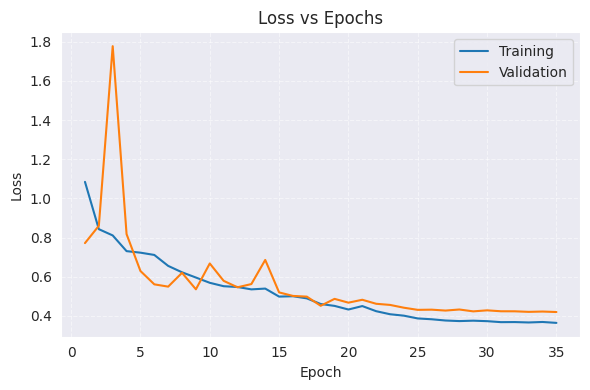

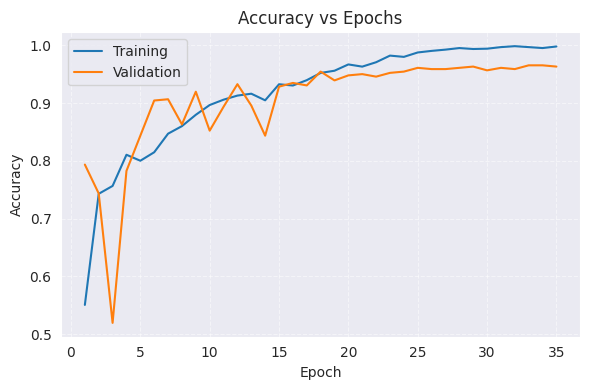

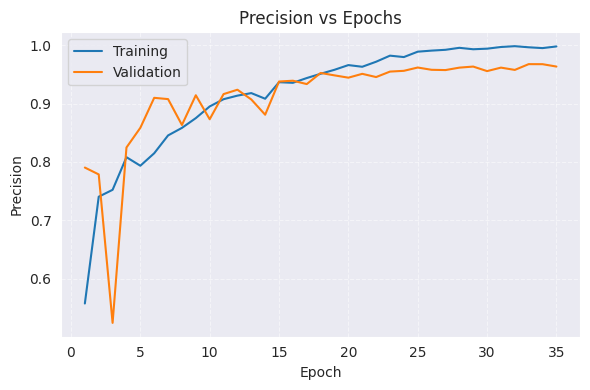

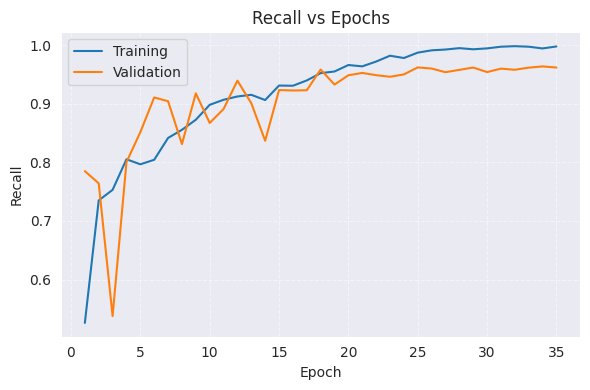

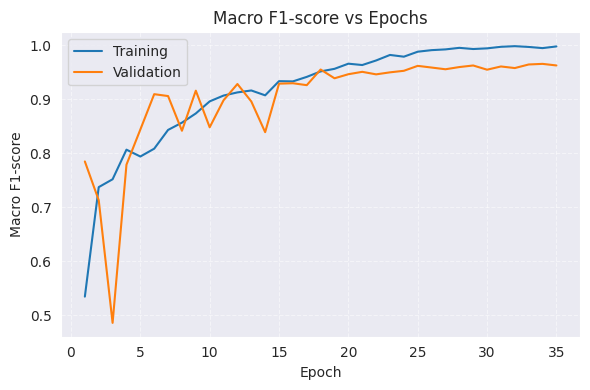

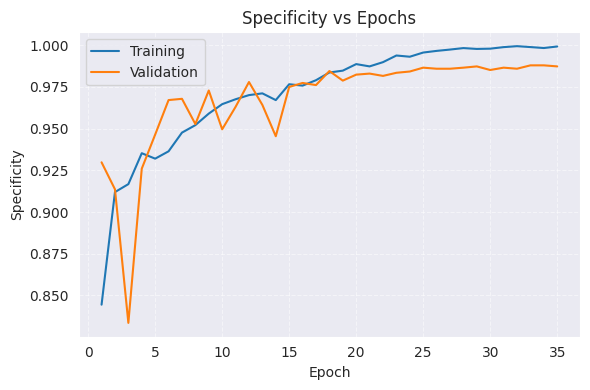

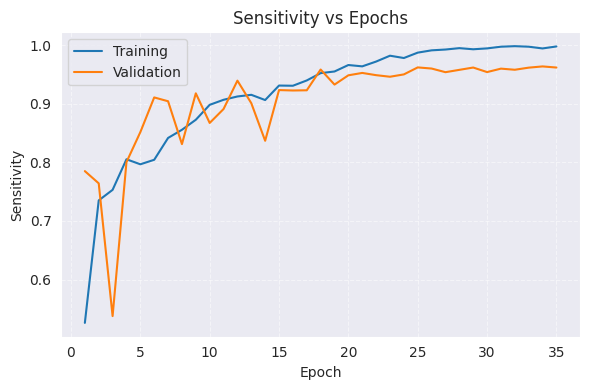

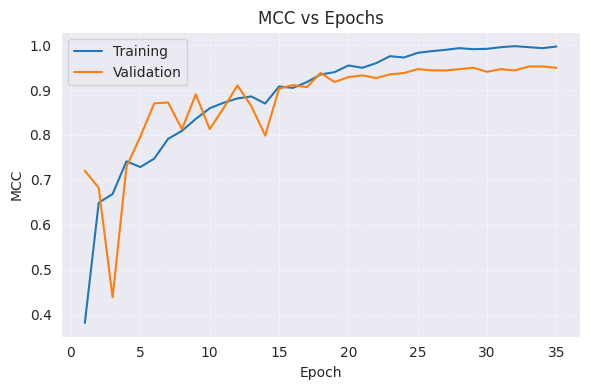

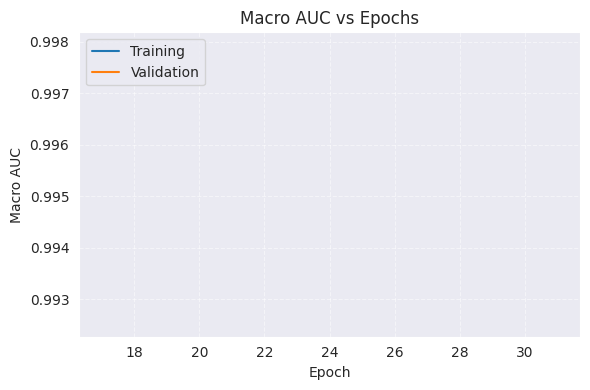

In [15]:
def plot_metric(train_values, val_values, title, ylabel):
    epochs = range(1, len(train_values) + 1)
    plt.figure(figsize=(6, 4))
    plt.plot(epochs, train_values, label="Training")
    plt.plot(epochs, val_values, label="Validation")
    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

plot_metric(history["loss"], history["val_loss"], "Loss vs Epochs", "Loss")
for metric, title in [
    ("accuracy", "Accuracy"), ("precision", "Precision"), ("recall", "Recall"),
    ("f1", "Macro F1-score"), ("specificity", "Specificity"),
    ("sensitivity", "Sensitivity"), ("mcc", "MCC"), ("auc", "Macro AUC")
]:
    plot_metric(history[metric], history[f"val_{metric}"], f"{title} vs Epochs", title)

## 14. Load best checkpoint and evaluate on the test set

In [16]:
checkpoint = torch.load(BEST_MODEL_PATH, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

all_targets, all_preds, all_probs = [], [], []
test_loss = 0.0
with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="Testing"):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, enabled=USE_AMP):
            outputs = model(images)
            loss = criterion(outputs, labels)
        test_loss += loss.item()
        all_targets.extend(labels.cpu().numpy())
        all_preds.extend(outputs.argmax(1).cpu().numpy())
        all_probs.extend(torch.softmax(outputs, dim=1).cpu().numpy())

all_targets = np.asarray(all_targets)
all_preds = np.asarray(all_preds)
all_probs = np.asarray(all_probs)
test_metrics = calculate_metrics(all_targets, all_preds, all_probs, num_classes)

print(f"Test loss: {test_loss / max(1, len(test_loader)):.4f}")
for key, value in test_metrics.items():
    print(f"{key}: {value:.4f}")

Testing:   0%|          | 0/72 [00:00<?, ?it/s]

Test loss: 0.4412
accuracy: 0.9599
precision: 0.9588
recall: 0.9553
f1: 0.9566
mcc: 0.9457
auc: nan
specificity: 0.9864
sensitivity: 0.9553


## 15. Classification report and confusion matrix

                  precision    recall  f1-score   support

    glioma_tumor     0.9422    0.9879    0.9645       165
meningioma_tumor     0.9806    0.9212    0.9500       165
        no_tumor     0.9481    0.9241    0.9359        79
 pituitary_tumor     0.9645    0.9879    0.9760       165

        accuracy                         0.9599       574
       macro avg     0.9588    0.9553    0.9566       574
    weighted avg     0.9605    0.9599    0.9597       574



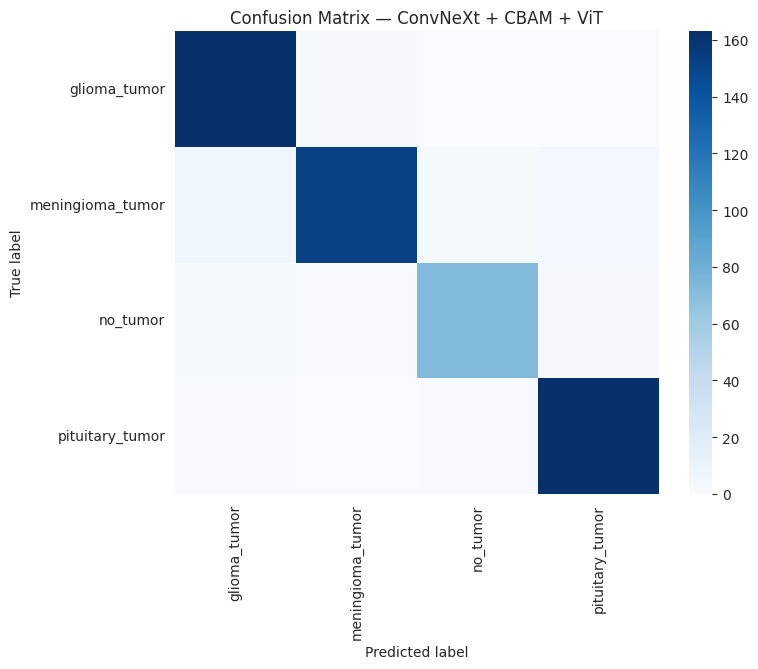

In [17]:
class_names = [idx_to_class[i] for i in range(num_classes)]
print(classification_report(
    all_targets, all_preds, labels=list(range(num_classes)),
    target_names=class_names, digits=4, zero_division=0
))

cm = confusion_matrix(all_targets, all_preds, labels=list(range(num_classes)))
fig_size = max(8, min(18, 0.45 * num_classes + 5))
plt.figure(figsize=(fig_size, fig_size * 0.85))
sns.heatmap(cm, cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Confusion Matrix — ConvNeXt + CBAM + ViT")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [18]:
experiment_summary = {
    "experiment": "Four-block ConvNeXt-Tiny + CBAM + ViT",
    "backbone": "convnext_tiny",
    "pretrained": True,
    "retained_stages": [0, 1],
    "retained_blocks_per_stage": retained_block_counts,
    "total_retained_convnext_blocks": int(sum(retained_block_counts)),
    "removed_stages": [2, 3],
    "input_shape": [3, 448, 448],
    "backbone_feature_map_shape": [192, 56, 56],
    "attention": "CBAM channel attention followed by spatial attention",
    "max_pool": {"kernel_size": 2, "stride": 2, "output_shape": [192, 28, 28]},
    "conv_1x1": {"input_channels": 192, "output_channels": 96},
    "conv_3x3": {"input_channels": 96, "output_channels": 64, "padding": 1},
    "vit": {
        "implementation": "timm.models.vision_transformer.VisionTransformer",
        "img_size": 28,
        "patch_size": 7,
        "in_chans": 64,
        "num_classes": 0,
        "embed_dim": 64,
        "depth": 2,
        "num_heads": 4,
        "mlp_ratio": 1,
        "mlp_hidden_dimension": 64,
        "mlp_activation": "ReLU",
        "qkv_bias": True,
        "head": "Identity",
        "input_format": "B, 64, 28, 28 (4D feature map passed directly; no manual flattening)"
    },
    "classifier": "Linear(64, num_classes); softmax applied for probabilities",
    "num_classes": int(num_classes),
    "class_to_idx": label_map,
    "best_validation_accuracy": float(best_val_acc),
    "test_metrics": {k: float(v) for k, v in test_metrics.items()},
    "total_parameters": int(total_params),
    "trainable_parameters": int(trainable_params),
    "thop_flops": int(flops)
}

with open("convnext_cbam_vit_results.json", "w") as f:
    json.dump(experiment_summary, f, indent=2)

print(json.dumps(experiment_summary, indent=2))


{
  "experiment": "Four-block ConvNeXt-Tiny + CBAM + ViT",
  "backbone": "convnext_tiny",
  "pretrained": true,
  "retained_stages": [
    0,
    1
  ],
  "retained_blocks_per_stage": [
    3,
    1
  ],
  "total_retained_convnext_blocks": 4,
  "removed_stages": [
    2,
    3
  ],
  "input_shape": [
    3,
    448,
    448
  ],
  "backbone_feature_map_shape": [
    192,
    56,
    56
  ],
  "attention": "CBAM channel attention followed by spatial attention",
  "max_pool": {
    "kernel_size": 2,
    "stride": 2,
    "output_shape": [
      192,
      28,
      28
    ]
  },
  "conv_1x1": {
    "input_channels": 192,
    "output_channels": 96
  },
  "conv_3x3": {
    "input_channels": 96,
    "output_channels": 64,
    "padding": 1
  },
  "vit": {
    "implementation": "timm.models.vision_transformer.VisionTransformer",
    "img_size": 28,
    "patch_size": 7,
    "in_chans": 64,
    "num_classes": 0,
    "embed_dim": 64,
    "depth": 2,
    "num_heads": 4,
    "mlp_ratio": 1,
    "ml